Programming for Data Analytics Assessment 2 

## Dataset Selection and Suitability 

The medical scheme wants to be able to identify customers who may qualify for dreaded disease benefits, starting with cancer. 

This analysis uses the Breast Cancer Wisconsin (Diagnostic) dataset  to classify breast tumor observations as either benign or malignant. Malignant observations are the class of interest because identifying these cases could help the medical scheme prioritise customers for dread disease benefits.

The dataset is suitable for this classification analysis because it has numerical predictors and a labeled target variable. The quality of the dataset is checked through missing value checks, duplicate checks and data type checks. 

The quality of the data: In addition to an id column and the diagnosis, the collection contains 569 records and 30 numerical tumour measurements (such as radius, texture, and area). No duplicate rows or missing values in the measurements were discovered during the checks. One column (Unnamed: 32) was removed because it was entirely empty. With 357 benign (about 63%) and 212 malignant (around 37%) cases, the diagnosis labels (B and M) are consistent. The reliability of the measurements is supported by the fact that they were computed using pictures of tumour samples and that the dataset is frequently used as a standard.

The dataset can be found here "https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29" 

## Algorithm Selection

Logistic regression has been chosen since the target variable consists of two categories: benign and malignant. It offers a simple baseline that is easy to implement and understand.

Given that the tumor measurements have varying numerical scales, StandardScaler is applied prior to classification.

Why other algorithms were not selected.

Although random forest and gradient boosting can be accurate, they require more tuning and are more difficult to explain to the medical scheme and its clients. The additional complexity is unlikely to make a significant difference with only 569 records and good numerical data.

Although a single decision tree is simple to describe, it is prone to overfitting small datasets and can alter significantly in response to slight variations in the data.

Support vector machines (with non-linear kernels) and K-nearest neighbours are susceptible to scaling and do not provide a clear explanation of which data lead to a prediction.

Logistic regression gives a probability that a tumour is malignant, so borderline cases can be flagged for review, and its coefficients show which measurements push a prediction towards malignant.

# Analysis Planning 

- Data cleaning - Check the data for missing values, duplicates, incorrect data types, and erroneous diagnosis labels. Get rid of the empty column and exclude the identifier from the set of predictors.
- EDA- Check class counts, the summary statistics, the distributions of the selected features, and the correlations.
- Feature selection - all 30 of the measurements should be kept as the baseline, followed by looking at a subset of 10 measurements using SelectKBest.
- Model training- use a stratified split with an 80/20 ratio and a pipeline that includes standardisation and logistic regression. Hyperparameters C and class_weight are tuned with GridSearch and five-fold stratified cross validation, scored on malignant recall.
- Evaluation- Compare accuracy, precision, recall, F1-score, and confusion matrices. Pay special attention to missed malignant cases.
- Reporting- Prepare the individual report based on the completed notebook entries.

# Importing Required Libraries 


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Train-test split 
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV

# Model
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

# Evaluation metrics 
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, make_scorer, recall_score

The necessary Python Libraries are imported to assist with performing data analysis

In [2]:
# Loading dataset 
df = pd.read_csv('data.csv')
print("Dataset shape:", df.shape)
df.head(20)

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750,NaN


## Loading Dataset and Display Data 

The Breast Cancer dataset for the analysis is loaded, the first 20 rows of the dataset and the shape of the data are displayed. The shape shows the number of rows and columns.

The dataset consists of 569 rows and 33 fields of data.

In [3]:
# Exploring the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

The columns and data types of the columns are inspected, as an attempt to get tot know the structure and the quality of the data.

In [4]:
# Exploring the dataset

print("columns:", df.columns.tolist())

#Check for missing values
print("Missing Values:", df.isnull().sum())

# Check for duplicated rows
print("Duplicated rows:", df.duplicated().sum())

columns: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
Missing Values: id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se              

The dataset is inspected to understand the structure and also to identify any anomalies in the dataset.
The dataset is checked for any missing values and duplicated rows. The "Unnamed:32" column had 569 missing values and no duplicated rows were identified.

In [5]:
# Remove the Unnamed: 32 column 

df = df.drop(columns=["Unnamed: 32"])
print("Missing Values:", df.isnull().sum())

Missing Values: id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


## Handling of Missing Values

569 missing values were identified under the column "Unnamed: 32". This means that the entire columns was empty 
As a result the column was removed because it was determined to have no usable information for the model. 

The dataset was then checked for missing values again after removing the column, and there were none left. 

In [6]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Target Variables and Predictors

The diagnosis column is the target variable for the classification model becuase it identifies each as either benign or malignant. The numerical tumor measurements are used as predictors


In [7]:
## Exploring the target variable (Diagnosis Column)

# Checking for missing diagnosis values
print("Missing diagnosis values:", df["diagnosis"].isnull().sum())

Missing diagnosis values: 0


No missing diagnosis were identified

In [8]:
# Check the count of each category
print("Diagnosis values:") 
print(df["diagnosis"].value_counts())

Diagnosis values:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [9]:
# standardise diagnosis labels 

df["diagnosis"] = df["diagnosis"].astype("string").str.strip().str.upper()

print("Diagnosis values after standardisation:", df["diagnosis"].value_counts())

Diagnosis values after standardisation: diagnosis
B    357
M    212
Name: count, dtype: int64[pyarrow]


## Standardising the diagnosis variables

The diagnosis values are standardised to uppercase and any whitespaces are removed for consistency and the cleaned values are displayed.

There are two classes are; 
B- Benign 
M- Malignant


In [10]:
# Counting each diagnosis class 

diagnosis_counts = df["diagnosis"].value_counts()
print(diagnosis_counts)

diagnosis
B    357
M    212
Name: count, dtype: int64[pyarrow]


There are 357 benign tumor and 212 malignant cases identified

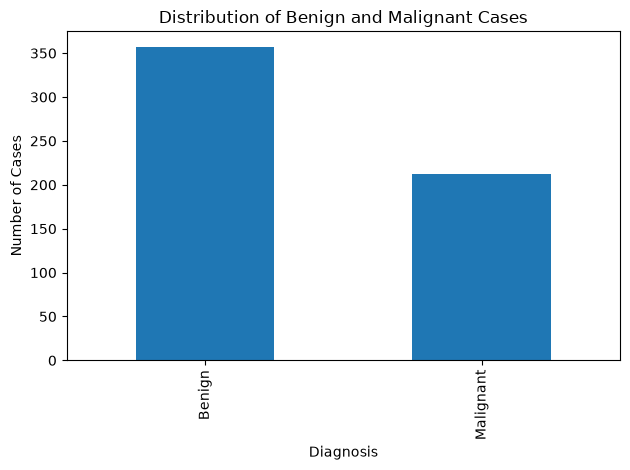

In [11]:
# Plot the distribution of diagnosis classes 
diagnosis_counts = df["diagnosis"].map({
    "B": "Benign", 
    "M": "Malignant"
}).value_counts()

diagnosis_counts.plot(kind="bar")

plt.title("Distribution of Benign and Malignant Cases") 
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases") 
plt.tight_layout()
plt.show()

This chart shows how many cases belong to each diagnosis class. It shows the distribution of benign and malignant cases in the dataset. The more common diagnosis is benign tumors, while malignant diagnosis are less common. 

In [12]:
# Identifying numerical tumour measurement features 
numeric_features = (
    df.drop(columns=["id"], errors="ignore")
        .select_dtypes(include="number")
        .columns.tolist()
)

print("Number of numerical columns:", len(numeric_features))
print("Numerical columns:")
print(numeric_features) 

# Summary statistics for numerical features
display(df[numeric_features].describe().T)
      

Number of numerical columns: 30
Numerical columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


The summary statistics refer to the 30 numerical measurements of the tumour.
The identifier "id" is excluded because it identifies observations rather than measuring tumour characteristics.

The measurements have different numerical scales, which supports including standardisation in the model pipeline.

The numerical columns in the dataset that are available to use for the analysis are identified using summary statistics. Their characteristics are also determined and inspected for values that might need more investigation.

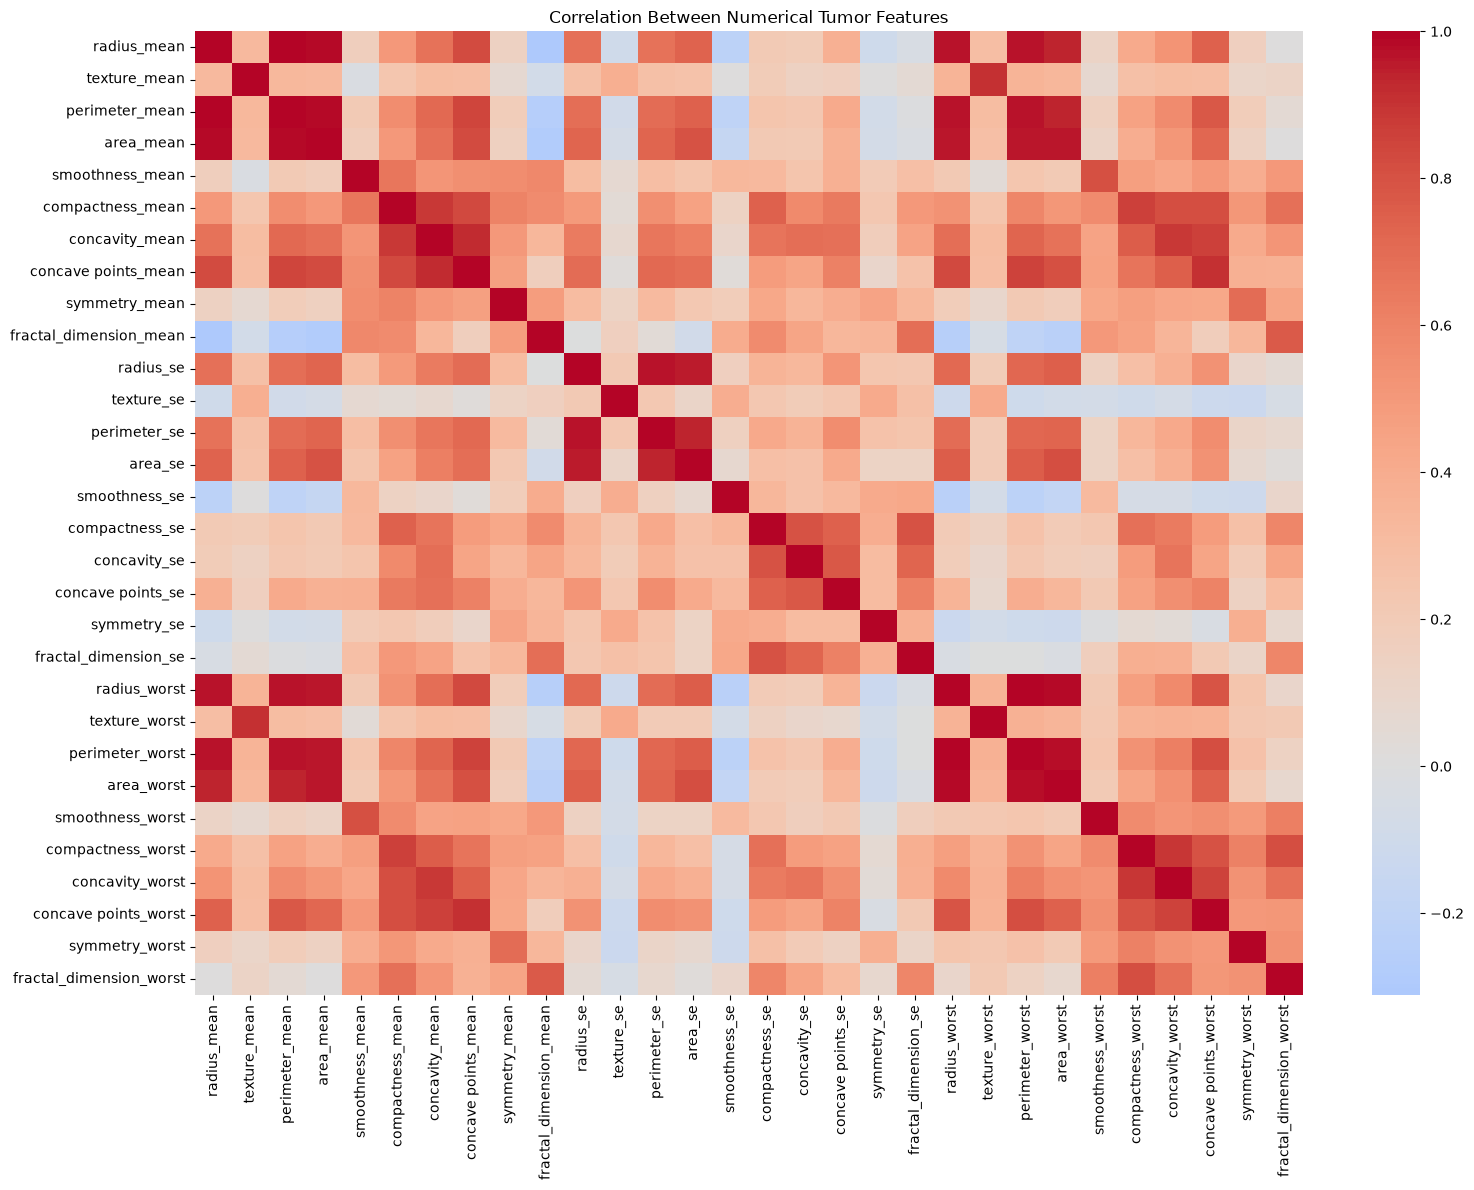

In [13]:
# Plot a correlation heat map 

# Select the numerical tumor measurements 
numeric_features = (
    df.drop(columns=["id"], errors = "ignore") 
        .select_dtypes(include="number")
        .columns.tolist()
)

# Calculate correlations between the numerical features 
correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix, 
    cmap="coolwarm", 
    center=0, 
    annot=False
)

plt.title("Correlation Between Numerical Tumor Features") 
plt.tight_layout()
plt.show()


In [14]:
# Examine six relationships between tumor size measurements 

print( 
    "Radius and perimeter correlation:", 
    round(df["radius_mean"].corr(df["perimeter_mean"]), 3)
)

print(
    "Radius and area correlation:", 
    round(df["radius_mean"].corr(df["area_mean"]), 3)
)

Radius and perimeter correlation: 0.998
Radius and area correlation: 0.987


The correlation between radius_mean and perimeter_mean is 0.998.
The correlation between radius_mean and area_mean is 0.987.

These relationships indicate that some tumour measurements contain
similar information. 

## Baseline Feature Preparation

In [15]:
# Defining the predictor variables and target variable

# Converting the diagnosis variables to word class labels 
y = df["diagnosis"].map({
    "B": "Benign", 
    "M": "Malignant"
})

# Selecting the numerical tumour measurements as predictors 
X = df.select_dtypes(include="number").copy()

# Removing the id column 
X = X.drop(columns=["id"], errors="ignore")

#Checking that the target labels were mapped correctly 
print("Target class counts:")
print(y.value_counts(dropna=False))

print("Predictor data shape:", X.shape)
print("Target data shape:", y.shape) 

print("Predictor columns:") 
print(X.columns.tolist())


Target class counts:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Predictor data shape: (569, 30)
Target data shape: (569,)
Predictor columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


The labels of the diagnosis columns are changed from B to Benign and M to Malignant for easier readability. 

The numerical tumor measurements are selected as the predictors for the model and the remaining unusable column "Id" is removed from the dataset.

In [16]:
# Splitting dataset into training and testing sets 

X_train, X_test, y_train, y_test = train_test_split( 
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Training feature shape:", X_train.shape) 
print("Testing feature shape:", X_test.shape) 

print("Training diagnosis distribution:")
print(y_train.value_counts(normalize=True)) 

print("Testing diagnosis distribution:") 
print(y_test.value_counts(normalize=True))



Training feature shape: (455, 30)
Testing feature shape: (114, 30)
Training diagnosis distribution:
diagnosis
Benign       0.626374
Malignant    0.373626
Name: proportion, dtype: float64
Testing diagnosis distribution:
diagnosis
Benign       0.631579
Malignant    0.368421
Name: proportion, dtype: float64


The diagnosis labels are mapped to Benign and Malignant for readability.

All 30 numerical tumour measurements are kept for the baseline
model. The identifier "id" is excluded from the predictors.

# Dataset Split 

The dataset is split into 80% for the training data and 20% for the testing data. 
Stratified splitting was used to preserve the proportions of benign and malignant cases in both the training and test dataset. 

The training data is used to fit models, and the test data is used to evaluate their predictions

## Comparison of Selected Measurements by Diagnosis

The following plots examine six measurements: radius_mean, area_mean, texture_mean, concavity_mean, concave points_mean and smoothness_mean using the training observations.

Histograms show distributions and overlap between the diagnosis groups.
Boxplots show medians, spread and potential outliers.

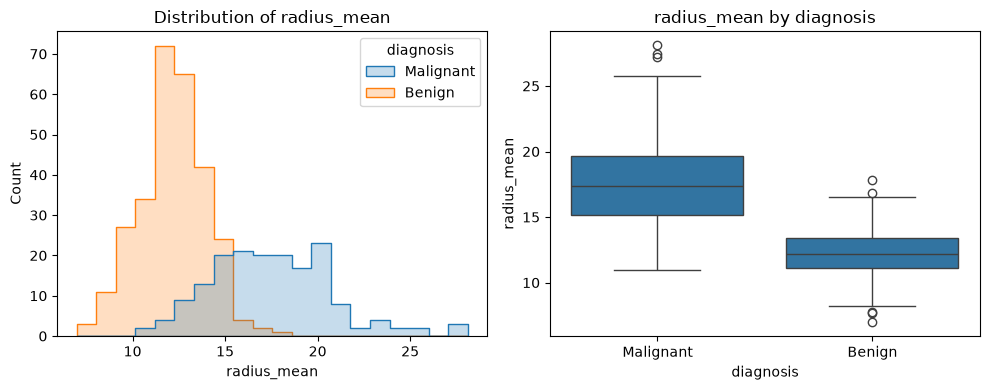

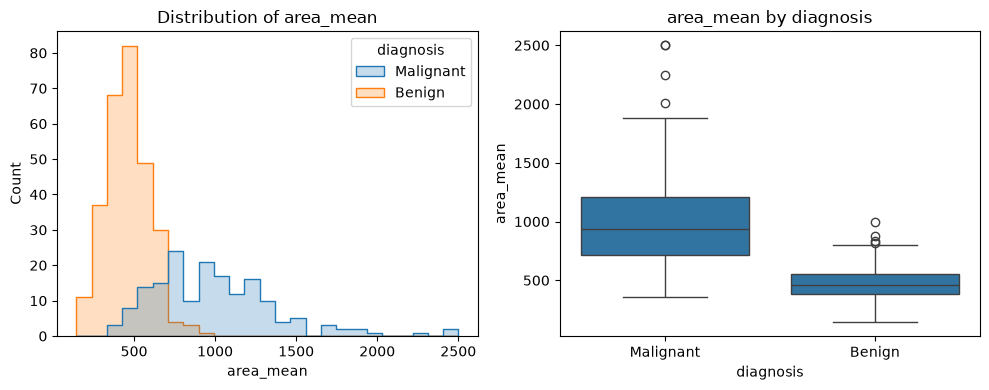

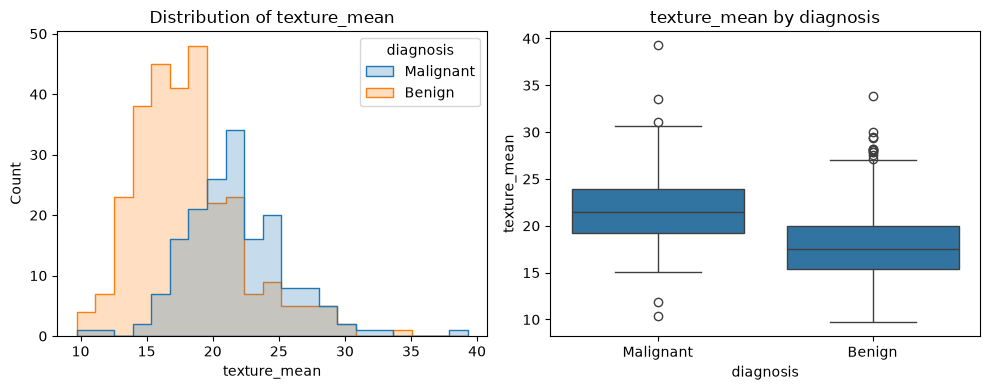

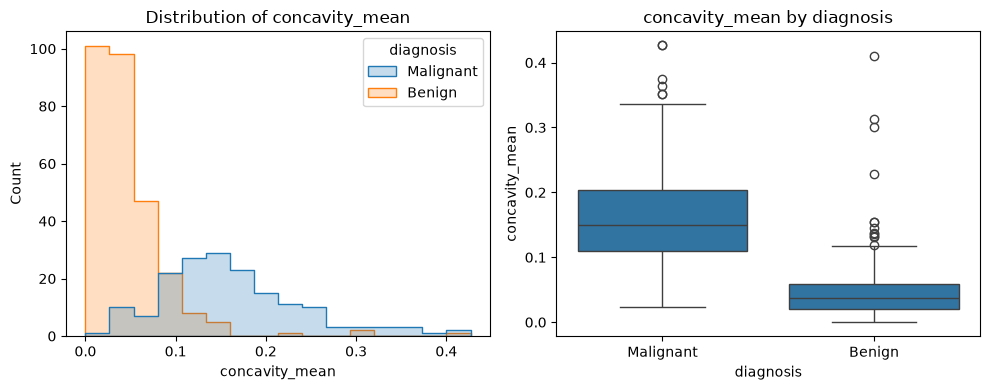

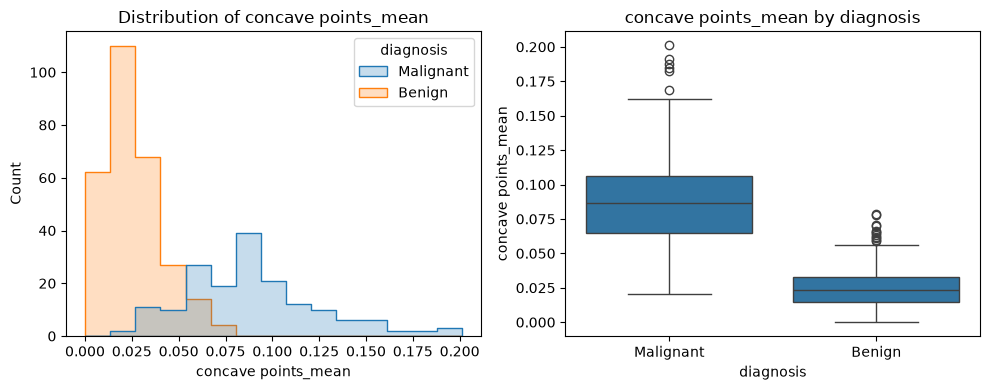

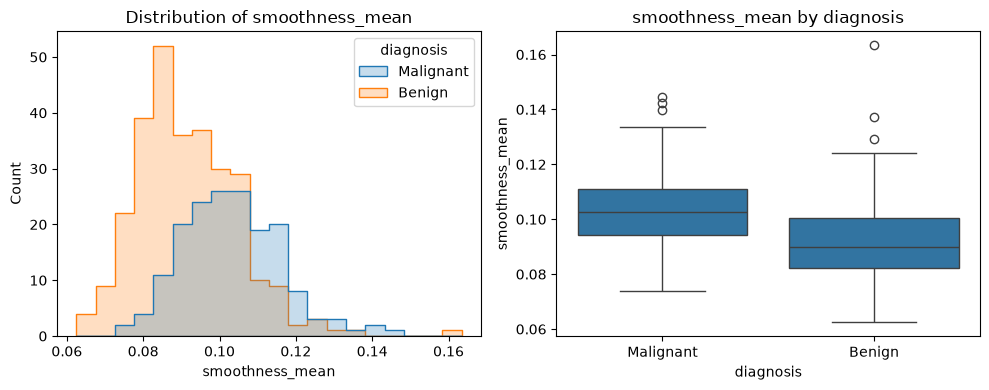

In [17]:
# Create a training-data table for exploratory comparisons.

eda_train = X_train.copy()
eda_train["diagnosis"] = y_train

# Examine two tumour measurements.
for feature in ["radius_mean", "area_mean", "texture_mean", "concavity_mean", "concave points_mean", "smoothness_mean"]:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.histplot(
        data=eda_train,
        x=feature,
        hue="diagnosis",
        element="step",
        ax=axes[0]
    )

    sns.boxplot(
        data=eda_train,
        x="diagnosis",
        y=feature,
        ax=axes[1]
    )

    axes[0].set_title(f"Distribution of {feature}")
    axes[1].set_title(f"{feature} by diagnosis")

    plt.tight_layout()
    plt.show()


In [18]:
print(
    eda_train.groupby("diagnosis")[
        ["radius_mean", "area_mean", "texture_mean", "concavity_mean", "concave points_mean", "smoothness_mean"]
        ].median()
)

           radius_mean  area_mean  texture_mean  concavity_mean  \
diagnosis                                                         
Benign          12.210     460.30         17.53         0.03709   
Malignant       17.385     940.45         21.52         0.14905   

           concave points_mean  smoothness_mean  
diagnosis                                        
Benign                 0.02331          0.08983  
Malignant              0.08639          0.10255  


For radius_mean, malignant observations have higher values although the two diagnosis may overlap.

For area_mean, malignant observations also have higer values and the two diagnosis tend to overlap
Potential outliers are retained because the analysis has not established that these observations have errors.
Malignant observations also tend to have higher concavity_mean and concave points_mean values with limited overlapping so these measurement separate the groups well. Texture_mean and smoothness_mean show more overlap between the groups so they are weaker on their own. These measurements give the model more information when they're together compared to on their own.

## Preprocessing 

In [19]:
# Creating a preprocessing and classfication pipeline 

model = Pipeline([
    ("Scaler", StandardScaler()), 
    ("Classifier", LogisticRegression(max_iter=2000))
])

print(model)

Pipeline(steps=[('Scaler', StandardScaler()),
                ('Classifier', LogisticRegression(max_iter=2000))])


StandardScaler standardises the numerical measurements before
classification. It is included inside the pipeline so that it is fitted
using the training data supplied to the model.

Logistic regression uses max_iter=2000 as its maximum number of
optimisation iterations.

## Model Training

In [20]:
# Train the baseline logistic regression model

model.fit(X_train, y_train) 

print("Baseline logistic regression model trained successfully.")

Baseline logistic regression model trained successfully.


The baseline logistic regression model was trained using the training tumour measurements and their corresponding diagnosis labels in the training dataset.

## Baseline Predictions





In [21]:
# Generate predictions for the test set 

y_pred = model.predict(X_test)

print("First 10 actual diagnosis:", y_test.head(10).tolist())

print("First 10 predicted diagnosis:", y_pred[:10].tolist())

First 10 actual diagnosis: ['Benign', 'Malignant', 'Benign', 'Malignant', 'Benign', 'Benign', 'Malignant', 'Benign', 'Benign', 'Benign']
First 10 predicted diagnosis: ['Benign', 'Malignant', 'Benign', 'Malignant', 'Malignant', 'Benign', 'Malignant', 'Benign', 'Benign', 'Benign']


## Classification report 

In [22]:
# Evaluate precision, recall and F1-score for each diagnosis class 

print(classification_report(
    y_test, 
    y_pred, 
    labels=["Benign", "Malignant"],
    zero_division=0
))
            

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Model Evaluation 


In [23]:
# Calculating model accuracy

accuracy = accuracy_score(y_test, y_pred)
print("Baseline accuracy:", round(accuracy, 4))

Baseline accuracy: 0.9649


The baseline logistic regression model achieved an accuracy of 96.49% on the test set. The report showed a benign recall of 99% and malignant recall of 93%.

The model correctly classified most observations, but 3 malignant observations were predicted as benign. The missed could be overlooked when the medical scheme prioritizes dread disease patients for benefits so malignant recall is therefore important when evaluating this model.

# Confusion Matrix

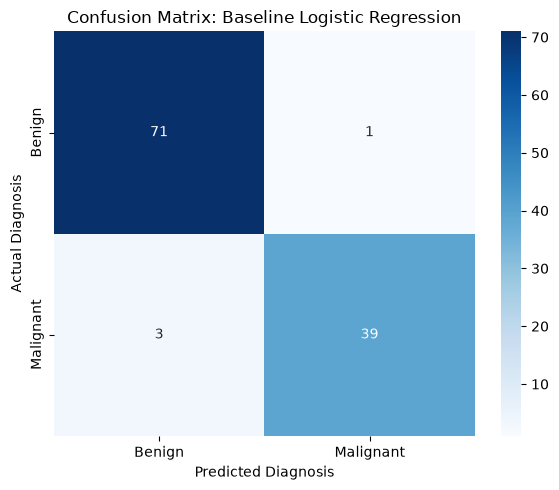

In [24]:
# Creating a confusion matrix 

labels = ["Benign", "Malignant"] 
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5)) 
sns.heatmap( 
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=labels, 
    yticklabels=labels

)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis") 
plt.title("Confusion Matrix: Baseline Logistic Regression")
plt.tight_layout()
plt.show()

The confusion matrix compares actual and predicted diagnosis labels. With malignant treated as the positive class, a false negative is a malignant observation predicted as benign. A false positive is a benign observation predicted as malignant.
Missed malignant observations are an important limitation. False positives also matter because they may lead to unnecessary further review.

## Feature Selection and Retraining

The baseline uses all 30 tumour measurements. This experiment uses SelectKBest with the ANOVA F-test to select 10 measurements according to their individual association with the diagnosis classes.
    
Ten features are chosen as a simple experimental subset, not as a proven optimal number.

The selected-feature model uses the same train-test split and logistic regression settings as the baseline. Only the feature-selection step is added, making the comparison easier to interpret.

Selection is based on each measurement's individual statistical association with diagnosis in the training data. This does not guarantee that the selected subset will improve predictions.

In [25]:
# Train a second model using 10 selected measurements.
selected_model = Pipeline([
    ("Scaler", StandardScaler()),
    ("Selection", SelectKBest(score_func=f_classif, k=10)),
    ("Classifier", LogisticRegression(max_iter=2000))
])

selected_model.fit(X_train, y_train)

print("Selected-feature model trained successfully.")

# Display the measurements retained by SelectKBest.
selected_mask = selected_model.named_steps[
    "Selection"
].get_support()

selected_features = X_train.columns[selected_mask]

print("Selected features:")
print(selected_features.tolist())

Selected-feature model trained successfully.
Selected features:
['radius_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'radius_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave points_worst']


The feature selection step kept the 10 measurements that were listed above. 

Selection is based on each measurements individual statistical association with diagnosis in the training data.

## Feature Selection Evaluation

Selected-feature model accuracy: 0.9561
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



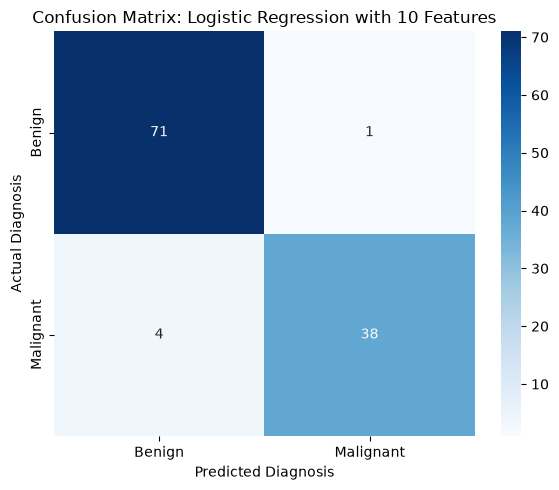

In [26]:
# Generate predictions from the selected-feature model.
selected_pred = selected_model.predict(X_test)

print(
    "Selected-feature model accuracy:",
    round(accuracy_score(y_test, selected_pred), 4)
)

print(classification_report(
    y_test,
    selected_pred,
    labels=["Benign", "Malignant"],
    zero_division=0
))

# Plot its confusion matrix.
selected_cm = confusion_matrix(
    y_test,
    selected_pred,
    labels=["Benign", "Malignant"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    selected_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("Confusion Matrix: Logistic Regression with 10 Features")
plt.tight_layout()
plt.show()

In [27]:
# Obtain evaluation values for both models.
baseline_report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

selected_report = classification_report(
    y_test,
    selected_pred,
    output_dict=True,
    zero_division=0
)

baseline_cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Benign", "Malignant"]
)

# Compare overall performance and malignant-class performance.
comparison = pd.DataFrame({
    "Model": [
        "Baseline: 30 features",
        "Selected model: 10 features"
        ],
        
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, selected_pred)
    ],
    "Malignant precision": [
        baseline_report["Malignant"]["precision"],
        selected_report["Malignant"]["precision"]
    ],
    "Malignant recall": [
        baseline_report["Malignant"]["recall"],
        selected_report["Malignant"]["recall"]
    ],
    "Malignant F1-score": [
        baseline_report["Malignant"]["f1-score"],
        selected_report["Malignant"]["f1-score"]
    ],
    "Missed malignant cases": [
        baseline_cm[1, 0],
        selected_cm[1, 0]
    ],
    "Benign cases flagged malignant": [
        baseline_cm[0, 1],
        selected_cm[0, 1]
    ]
})

display(comparison.round(4))

,Model,Accuracy,Malignant precision,Malignant recall,Malignant F1-score,Missed malignant cases,Benign cases flagged malignant
0,Baseline: 30 features,0.9649,0.9750,0.9286,0.9512,3,1
1,Selected model: 10 features,0.9561,0.9744,0.9048,0.9383,4,1


The baseline used 30 measurements, while the second model used
10 selected measurements.

The baseline achieved accuracy of 96.49% and malignant recall of 92.86%, with 3 missed malignant observations.

The selected-feature model achieved accuracy of 95.61% and malignant recall of 90.48%, with 4 missed malignant observations. Using fewer features reduced accuracy and malignant recall.

Both models incorrectly classified 1 benign observation as malignant.

The baseline model performed better on the test set becayse it identified one more malignant observation without increasing the number of false positives. So it was retained as the preferred model for this analysis. 

This is a limited comparison using one train-test split. 

## Baseline Model Five-Fold Cross-Validation

The baseline model is evaluated across several training data partitions using five-fold stratified cross-validation.

Malignant recall and accuracy are noted. In order to fit standardisation independently within each fold, the entire pipeline is assessed. This does not include the held-out test set.

In [28]:
# Create five stratified folds.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Measure recall for malignant observations.
malignant_recall = make_scorer(
    recall_score,
    pos_label="Malignant",
    zero_division=0
)

In [29]:
# Evaluate the baseline pipeline using training data only.
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "malignant_recall": malignant_recall
    },
    error_score="raise"
)

In [30]:
# Show validation scores for each fold.
cv_table = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": cv_results["test_accuracy"],
    "Malignant recall": cv_results["test_malignant_recall"]
})

display(cv_table.round(4))

# Summarise performance across the folds.
print(
    "Mean CV accuracy:",
    round(cv_table["Accuracy"].mean(), 4)
)

print(
    "Mean CV malignant recall:",
    round(cv_table["Malignant recall"].mean(), 4)
)

print(
    "CV accuracy standard deviation:",
    round(cv_results["test_accuracy"].std(), 4)
)

print(
    "CV malignant recall standard deviation:",
    round(cv_results["test_malignant_recall"].std(), 4)
)

,Fold,Accuracy,Malignant recall
0,1,0.956,0.8824
1,2,0.967,0.9706
2,3,1.000,1.0000
3,4,0.978,0.9412
4,5,0.967,0.9706


Mean CV accuracy: 0.9736
Mean CV malignant recall: 0.9529
CV accuracy standard deviation: 0.0149
CV malignant recall standard deviation: 0.0399


### Results of Cross-Validation

The baseline obtained a mean malignant recall of 95.29% over five folds and a mean cross-validation accuracy of 97.36%.

The variation across the folds was displayed by the standard deviation, which was 0.0149 for accuracy and 0.0399 for malignant recall.

Using the training data, cross-validation offered further assessment. New hyperparameters were not chosen using it. The findings of the held-out test set are presented independently.

In [31]:
## Grid search: try different settings and keep the one with the best malignant recall


param_grid = {
    "Classifier__C": [0.01, 0.1, 1, 10, 100],
    "Classifier__class_weight": [None, "balanced"]
}

grid = GridSearchCV(model, param_grid, cv=cv, scoring=malignant_recall)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated malignant recall:", round(grid.best_score_, 4))

# Check the tuned model once on the test set
tuned_pred = grid.best_estimator_.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print(classification_report(y_test, tuned_pred, labels=["Benign", "Malignant"], zero_division=0))
print(confusion_matrix(y_test, tuned_pred, labels=["Benign", "Malignant"]))


Best settings: {'Classifier__C': 1, 'Classifier__class_weight': 'balanced'}
Best cross-validated malignant recall: 0.9588
Test accuracy: 0.9737
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

[[71  1]
 [ 2 40]]


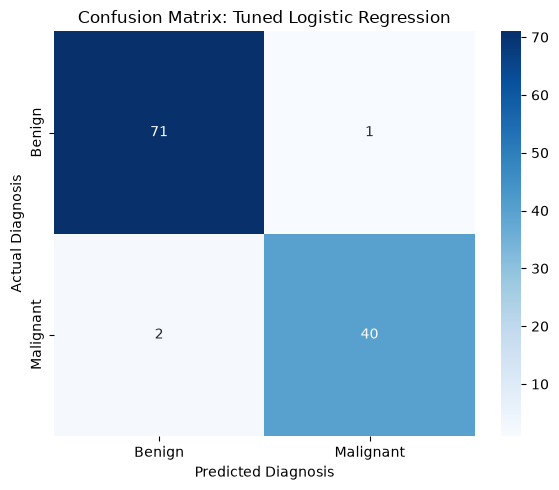

In [32]:
# Confusion matrix for the tuned model
labels = ["Benign", "Malignant"]
tuned_cm = confusion_matrix(y_test, tuned_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("Confusion Matrix: Tuned Logistic Regression")
plt.tight_layout()
plt.show()

# Grid Search to Tune logistic Regression 

Grid search tries every combination of the chosen settings and keeps the one with the best cross validated score. In this analysis it tests five values of C (regularisation strength) and the two class_weight settings, using fivefold stratified cross validation on the training data, scored on malignant recall.

In [33]:
# Show the predicted probability of malignancy for the first 5 test cases
print(grid.best_estimator_.predict_proba(X_test)[:5].round(3))
print(grid.best_estimator_.classes_)

[[0.999 0.001]
 [0.    1.   ]
 [0.946 0.054]
 [0.32  0.68 ]
 [0.355 0.645]]
['Benign' 'Malignant']


The column order matches the printed classes, so the malignant column can be read as the probability.

The optimal settings were C = 1 and class_weight = "balanced," resulting in a cross-validated malignant recall of 95.88%. On the test set, the tuned model had an accuracy of 97.37% and a malignant recall of 95.24%, missing two malignant cases and labeling one benign case as malignant, compared to three missed and one flagged in the baseline. Tuning improved slightly over the baseline, hence the tuned model is recommended. The improvement is minor, as it is one extra malignant case detected out of 42, so proceed with caution. The settings were determined using cross-validation on only the training data, not the test set. 

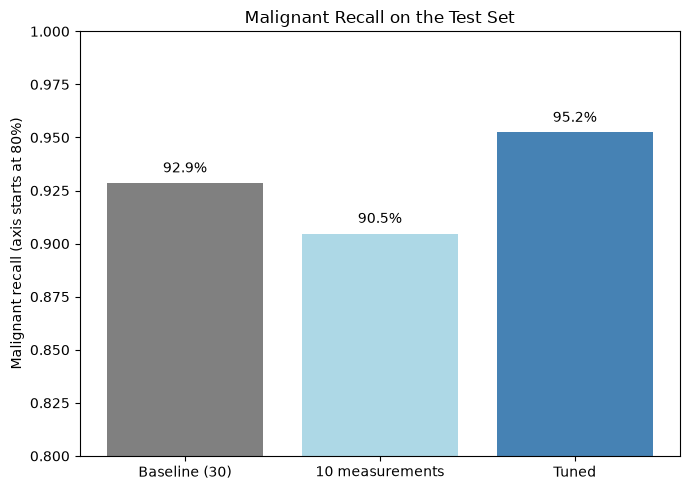

In [34]:
# Compare malignant recall across the three models on the test set

model_names = ["Baseline (30)", "10 measurements", "Tuned"]
recalls = [
    recall_score(y_test, p, pos_label="Malignant")
    for p in (y_pred, selected_pred, tuned_pred)
]

plt.figure(figsize=(7, 5))
bars = plt.bar(model_names, recalls, color=["grey", "lightblue", "steelblue"])
for bar, value in zip(bars, recalls):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.005, f"{value:.1%}", ha="center")
plt.ylim(0.8, 1.0)
plt.ylabel("Malignant recall (axis starts at 80%)")
plt.title("Malignant Recall on the Test Set")
plt.tight_layout()
plt.show()

This chart shows the malignant diagnosis recall across the models used in the analysis. The tuned model was able to predict the most malignant cases but the gap was small. 

## Summary and Limitations

This notebook completed data cleaning, exploratory analysis, baseline
logistic regression training, feature selection and a comparison of
two feature configurations.

The main finding was that the tuned logistic regression model (C = 1, class_weight = "balanced") performed best on the test set, with an accuracy of 97.37% and a malignant recall of 95.24%. It missed 2 malignant cases, compared with 3 for the baseline (all 30 measurements, default settings) and 4 for the 10-feature model.

Five-fold stratified cross-validation was also conducted using the training data to assess the baseline accuracy and malignant recall across the different groupings. 

The analysis has several limitations:

- The dataset concerns breast tumour classification rather than all cancers.
- Results are based on a single train-test split.
- The feature subset was not established as optimal.
- Classification errors remain important when interpreting performance.
- The test set has only 42 malignant cases, so a single case changes malignant recall by about 2.4 percentage points.
